In [1]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=UserWarning)

import numpy as np
import os
import matplotlib.pyplot as plt
import scipy

import random
import torch
import torchaudio
import librosa
import matplotlib.pyplot as plt

import pysptk
import scipy.signal as sps
import scipy.ndimage as ndi

import matplotlib as mpl

mpl.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 9,
    "axes.labelsize": 9,
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})

## Define paths:

In [2]:
filepath_dev = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_dev"
filepath_eval = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval"
savepath = "/home/smg/v-viola/moe_antideepfake/figures"

## Functions:

In [5]:
def load_tracks(filename_r, filename_f):
    path_r = f'{filepath_eval}/flac/{filename_r}.flac'
    path_f = f'{filepath_dev}/flac/{filename_f}.flac'
    xr = load_audio_track(path_r)
    xf = load_audio_track(path_f)
    
    return xr, xf

def load_audio_track(path, trim=True, normalize=True, sr=16000, top_db=40):
    waveform, sample_rate = librosa.load(path, sr=None, mono=True)
    waveform = torch.Tensor(waveform).unsqueeze(0)  # gotta fix torchaudio.load

    if sr != sample_rate:
        resampler = torchaudio.transforms.Resample(orig_freq=sample_rate, new_freq=sr)
        waveform = resampler(waveform)
    if normalize:
        peak = waveform.abs().max()
        if peak > 0:
            waveform = waveform / peak
    if trim:
        amplitude_threshold = 10 ** (-top_db / 20)
        non_silent = (waveform.abs() > amplitude_threshold).nonzero(as_tuple=True)[1]
        if non_silent.numel() > 0:
            start = non_silent[0].item()
            end = non_silent[-1].item() + 1
            waveform = waveform[:, start:end]
        else:
            waveform = waveform[:, :0]

    return waveform.squeeze()


def extract_and_plot_f0(waveform, filename, is_spoof=False, save_fig=False):
    x = np.copy(waveform)
    x = librosa.effects.preemphasis(x)
    autocorr_win_len = 256 // 2
    f0_trajectory, _, _ = librosa.pyin(x, sr=16000, frame_length=256, hop_length=256, center=True, win_length=autocorr_win_len, fmin=70, fmax=400, n_thresholds=7)

    plt.figure(figsize=(7, 2))
    if is_spoof:
        plt.plot(f0_trajectory, color='red', lw=2)
    else:
        plt.plot(f0_trajectory, color='blue', lw=2)
    plt.ylim([150, 350])
    plt.xlabel("Timeframes")
    plt.ylabel("Hz")
    plt.grid(True)
    if is_spoof:
        plt.title(f"Synthetic F0 Trajectory ({filename}.flac)")
    else:
        plt.title(f"Real F0 Trajectory ({filename}.flac)")

    if save_fig:
        if is_spoof:
            plt.savefig(f"{savepath}/f0_fake.pdf", format="pdf", bbox_inches="tight")
        else:
            plt.savefig(f"{savepath}/f0_real.pdf", format="pdf", bbox_inches="tight")
    else:
        plt.show()


def plot_lsf(waveform, filename, is_spoof=False, save_fig=False):
    
    def lsf_extraction(waveform):
        waveform = np.asarray(waveform, dtype=np.float64)
        waveform = waveform + 1e-6 * np.random.randn(len(waveform))
        waveform = waveform.astype(np.float64)
        frames = [waveform[i:i + 256] for i in range(0, len(waveform) - 256, 256)]
        frames = np.stack(frames)
        window = scipy.signal.get_window('blackman', 256, fftbins=False)
        windowed_frames = frames * window
        lpc_coeffs = pysptk.lpc(windowed_frames, 20)
        
        try:
            lsf = pysptk.lpc2lsp(lpc_coeffs)
            return lsf
        except RuntimeError:
            gamma = 0.9
            lpc_stable = lpc_coeffs * (gamma ** np.arange(lpc_coeffs.shape[1]))
            return pysptk.lpc2lsp(lpc_stable)
            
        return lsf
    
    lsf = lsf_extraction(waveform)
    
    fig = plt.figure(figsize=(7, 2))
    plt.plot(lsf, alpha=0.8)
    plt.grid(True, alpha=0.3)
    plt.yticks([])
    plt.xlabel("Timeframes")
    plt.ylabel("LSF Order")
    plt.tight_layout()
    
    if is_spoof:
        plt.title(f"Synthetic Line Spectral Frequencies ({filename}.flac)")
    else:
        plt.title(f"Real Line Spectral Frequencies ({filename}.flac)")
    
    if save_fig:
        if is_spoof:
            plt.savefig(f"{savepath}/ovs_fake.pdf", format="pdf", bbox_inches="tight")
        else:
            plt.savefig(f"{savepath}/ovs_real.pdf", format="pdf", bbox_inches="tight")
    else:
        plt.show()

        
def extract_and_plot_energy(wav1, wav2, filenames, first_is_spoof=False, save_fig=False):

    def spec_extraction_with_energy(y):
        spec_transform = torchaudio.transforms.Spectrogram(
            n_fft=512,
            hop_length=256,
            power=2)
        spec = spec_transform(torch.Tensor(y).unsqueeze(0)).squeeze(0)  
        feat = torchaudio.functional.amplitude_to_DB(
            spec,
            multiplier=10.0,
            amin=1e-10,
            db_multiplier=0)
        energy = spec.sum(dim=0) 
        return energy

    def plot_energy_curves(energy1_norm, energy2_norm, filenames):
        plt.figure(figsize=(7, 2))
        plt.plot(energy2_norm, color='blue', lw=2)
        plt.ylim([0, 1.1])
        plt.xlabel("Timeframes")
        plt.ylabel("Normalized Energy")
        plt.grid(True)
        plt.tight_layout()
        plt.title(f"Real Energy Curve ({filenames[1]}.flac)")
        if save_fig:
            plt.savefig(f"{savepath}/figures/energy_real.pdf", format="pdf", bbox_inches="tight")
        else:
            plt.show()
            
        plt.figure(figsize=(7, 2))
        plt.plot(energy1_norm, color='red', lw=2)
        plt.ylim([0, 1.1])
        plt.xlabel("Timeframes")
        plt.ylabel("Normalized Energy")
        plt.grid(True)
        plt.tight_layout()
        plt.title(f"Synthetic Energy Curve ({filenames[0]}.flac)")
        if save_fig:
            plt.savefig(f"{savepath}/figures/energy_fake.pdf", format="pdf", bbox_inches="tight")
        else:
            plt.show()
    
    energy1 = spec_extraction_with_energy(wav1)
    energy2 = spec_extraction_with_energy(wav2)
    
    global_min = min(energy1.min(), energy2.min())
    global_max = max(energy1.max(), energy2.max())
    
    energy1_norm = (energy1 - global_min) / (global_max - global_min)
    energy2_norm = (energy2 - global_min) / (global_max - global_min)

    if first_is_spoof:
        plot_energy_curves(energy1_norm, energy2_norm, filenames)
    else:
        tmp = energy1_norm
        tmp_f = filenames[0]
        filenames[0] = filenames[1]
        filenames[1] = tmp_f
        energy1_norm = energy2_norm 
        energy2_norm = tmp
        plot_energy_curves(energy1_norm, energy2_norm, filenames)
        
    
def plot_upsampling_feature(
    x,
    filename, 
    is_spoof=False,
    save_fig=False
):
    x = np.asarray(x, dtype=np.float32)
    f, t, Z = sps.stft(
        x, fs=16000,
        nperseg=512, noverlap=512 - 256,
        boundary=None, padded=False,)

    S = np.abs(Z)
    S_mean = np.mean(S, axis=1)  
    mask = (f >= 1000) & (f <= 8000)
    S_mean = S_mean[mask] 
    baseline = ndi.minimum_filter1d(S_mean, size=32)
    fingerprint = S_mean - baseline
    fingerprint = np.maximum(fingerprint, 0.0) 
    fingerprint /= (np.linalg.norm(fingerprint) + 1e-8) 
    fingerprint.astype(np.float32)

    plt.figure(figsize=(7, 2))
    if is_spoof:
        plt.plot(fingerprint, color='red')
    else:
        plt.plot(fingerprint, color='blue')
    plt.ylim([0, 0.8])
    plt.grid(True)
    plt.xlabel("Frequency bins")
    plt.ylabel("Amplitude")
    plt.tight_layout()

    if is_spoof:
        plt.title(f"Synthetic Peak-enhanced Spectrum ({filename}.flac)")
    else:
        plt.title(f"Real Peak-enhanced Spectrum ({filename}.flac)")

    if save_fig:
        if is_spoof:
            plt.savefig(f"{savepath}/ups_fake.pdf", format="pdf", bbox_inches="tight")
        else:
            plt.savefig(f"{savepath}/ups_real.pdf", format="pdf", bbox_inches="tight")
    else:
        plt.show()

## F0 trajectories

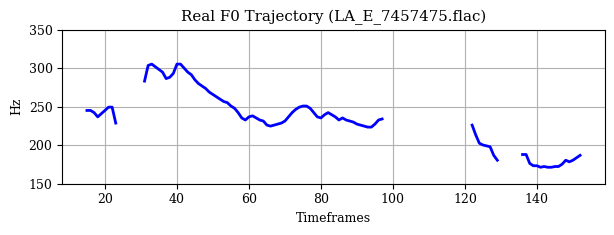

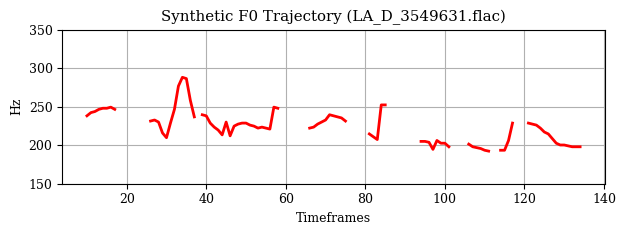

In [6]:
filename_r = 'LA_E_7457475'
filename_f = 'LA_D_3549631' 
xr, xf = load_tracks(filename_r, filename_f)

extract_and_plot_f0(xr, filename_r, is_spoof=False)
extract_and_plot_f0(xf, filename_f, is_spoof=True)

## Line Spectral Frequencies

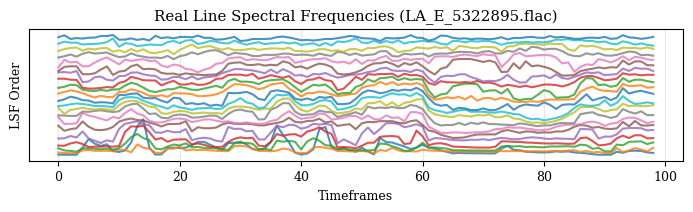

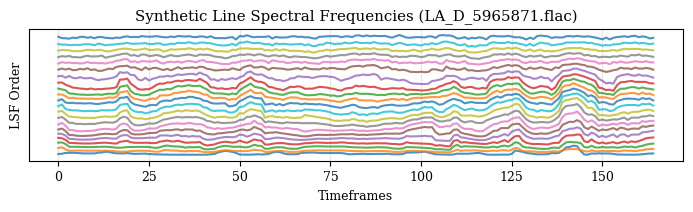

In [7]:
filename_r = 'LA_E_5322895'  
filename_f = 'LA_D_5965871' 
xr, xf = load_tracks(filename_r, filename_f)

plot_lsf(xr, filename=filename_r, is_spoof=False)
plot_lsf(xf, filename=filename_f, is_spoof=True)

## Energy Curves

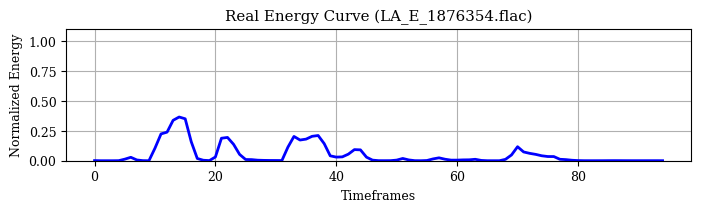

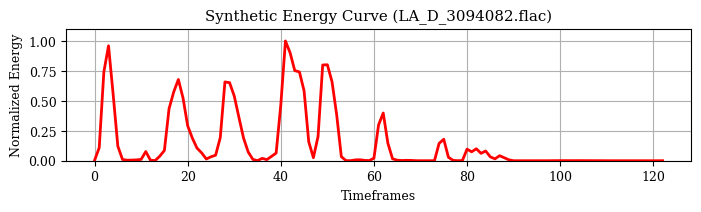

In [8]:
filename_r = 'LA_E_1876354'  
filename_f = 'LA_D_3094082' 
xr, xf = load_tracks(filename_r, filename_f)

extract_and_plot_energy(xr, xf, [filename_r, filename_f], first_is_spoof=False)

## Spectral Fingerprint

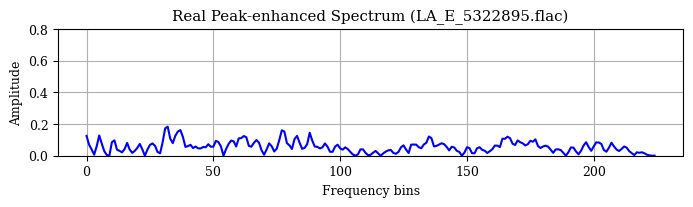

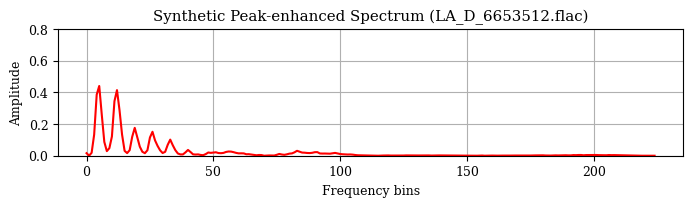

In [9]:
filename_r = 'LA_E_5322895'  
filename_f = 'LA_D_6653512' 
xr, xf = load_tracks(filename_r, filename_f)

plot_upsampling_feature(xr, filename_r, is_spoof=False)
plot_upsampling_feature(xf, filename_f, is_spoof=True)